# 13 · Plate reader: layout head

Notebook 07 (the base, no extra augmentation) with one extra head on the backbone that predicts how the plate should look: how many digits, districts,
letters and words it has. It is trained together with detection, with targets counted from the existing character
labels. Notebook 14 can use this per-plate layout when it reads the plate. Every other step is the same as notebook 05: same model, epochs, batch, optimizer setting, test and plate-text scoring.

In [1]:
%pip install -q ultralytics==8.4.46

Note: you may need to restart the kernel to use updated packages.


## Configuration

In [2]:
EXPERIMENT = "reader-layout"

EXPERIMENTS = {
    "reader-layout": {"model": "yolo26s.pt", "batch": 64},
}
EPOCHS = 150
IMGSZ = 320
SEED = 0

## Setup

In [3]:
import json
import shutil
from pathlib import Path

import pandas as pd
import torch
from ultralytics import YOLO

config = EXPERIMENTS[EXPERIMENT]
WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
RUNS = WORK / "runs"

gpus = torch.cuda.device_count()
DEVICE = ",".join(str(i) for i in range(gpus)) if gpus else "cpu"

# copy the dataset so Ultralytics can write its label cache
DATA = WORK / "plate-reading"
if not DATA.exists():
    shutil.copytree(next(p for p in INPUT.rglob("bangla-plate-reading") if p.is_dir()), DATA)
DATA_YAML = DATA / "data.yaml"
RUN = RUNS / EXPERIMENT
WEIGHTS = RUN / "weights" / "best.pt"
CLASSES = json.loads((DATA / "classes.json").read_text(encoding="utf-8"))

print(f"Experiment: {EXPERIMENT}  {config}\nDevice: {DEVICE}")
for split in ("train", "val", "test"):
    print(f"{split:5} {len(list((DATA / 'images' / split).iterdir())):6d} crops")

Experiment: reader-layout  {'model': 'yolo26s.pt', 'batch': 64}
Device: 0,1
train   6294 crops
val     1448 crops
test     778 crops


## Custom layer

Written to a file so the training processes on both GPUs can import it.

In [4]:
%%writefile /kaggle/working/plate_layers.py
import json
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import deform_conv2d
from ultralytics.models.yolo.detect import DetectionTrainer
from ultralytics.nn.modules import Conv
from ultralytics.nn.modules.block import Bottleneck
from ultralytics.nn.tasks import DetectionModel
from ultralytics.utils import RANK
import ultralytics.utils.torch_utils as torch_utils

KINDS = ["digit", "district", "letter", "word"]


# ---------------------------------------------------------------- deformable convolution (notebook 10)

class DConv(nn.Module):
    """Deformable 3x3 convolution (DCNv2) made from a pretrained Conv.

    The offsets start at zero and the mask at one, so before training it gives exactly the same output
    as the Conv it replaces; training then learns where each kernel tap should look.
    """

    def __init__(self, conv):
        super().__init__()
        c = conv.conv
        self.weight = nn.Parameter(c.weight.detach().clone())
        self.stride, self.padding, self.dilation = c.stride, c.padding, c.dilation
        taps = c.kernel_size[0] * c.kernel_size[1]
        self.offset = nn.Conv2d(c.in_channels, 3 * taps, c.kernel_size, c.stride, c.padding)
        nn.init.zeros_(self.offset.weight)
        nn.init.zeros_(self.offset.bias)
        self.bn = conv.bn
        self.act = conv.act

    def forward(self, x):
        dy_dx_1, dy_dx_2, mask = self.offset(x).chunk(3, dim=1)
        offset = torch.cat([dy_dx_1, dy_dx_2], dim=1)
        y = deform_conv2d(x, offset, self.weight, None, self.stride, self.padding, self.dilation, 2 * torch.sigmoid(mask))
        return self.act(self.bn(y))


# Ultralytics counts FLOPs with thop on an uninitialised tensor and the deformable op crashes on it.
# The count is only for the printed summary, so it is skipped for models with deformable convs.
_get_flops = torch_utils.get_flops


def _get_flops_safe(model, imgsz=640):
    if any(isinstance(m, DConv) for m in model.modules()):
        return 0.0
    return _get_flops(model, imgsz)


torch_utils.get_flops = _get_flops_safe


def add_dcn(model, layers=(6, 8)):
    """Swap the 3x3 conv of every bottleneck in backbone layers 6 and 8 (P4 and P5) for a DConv."""
    swapped = 0
    for i in layers:
        for m in model.model[i].modules():
            if isinstance(m, Bottleneck) and isinstance(m.cv2, Conv) and m.cv2.conv.kernel_size == (3, 3) \
                    and m.cv2.conv.stride == (1, 1) and m.cv2.conv.groups == 1:
                m.cv2 = DConv(m.cv2)
                swapped += 1
    return swapped


class DCNTrainer(DetectionTrainer):
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = super().get_model(cfg, weights, verbose)
        print("deformable convs:", add_dcn(model))
        return model


# ---------------------------------------------------------------- SPD-Conv (notebook 12)

class SPDConv(nn.Module):
    """Space-to-depth then a stride-1 conv: halves the size without dropping any pixel (SPD-Conv)."""

    def __init__(self, c1, c2):
        super().__init__()
        self.conv = Conv(4 * c1, c2, 3, 1)

    def forward(self, x):
        x = torch.cat([x[..., ::2, ::2], x[..., 1::2, ::2], x[..., ::2, 1::2], x[..., 1::2, 1::2]], dim=1)
        return self.conv(x)


def add_spd(model, layers=(1, 3, 5, 7)):
    """Replace the stride-2 Conv layers of the backbone (the downsampling to P2, P3, P4 and P5) with SPDConv."""
    for i in layers:
        old = model.model[i]
        new = SPDConv(old.conv.in_channels, old.conv.out_channels)
        new.f, new.i, new.type = old.f, old.i, "SPDConv"
        new.np = sum(p.numel() for p in new.parameters())
        model.model[i] = new
    return len(layers)


class SPDTrainer(DetectionTrainer):
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = super().get_model(cfg, weights, verbose)
        print("SPD layers:", add_spd(model))
        return model


# ---------------------------------------------------------------- layout head (notebook 13)

class Tap(nn.Module):
    """Wraps one backbone layer and keeps its last output, so the layout head can read it."""

    def __init__(self, m):
        super().__init__()
        self.m = m
        self.f, self.i, self.type, self.np = m.f, m.i, m.type, m.np
        self.out = None

    def forward(self, x):
        self.out = self.m(x)
        return self.out

    def __getstate__(self):
        state = self.__dict__.copy()
        state["out"] = None   # never save a feature map with the model
        return state


class LayoutHead(nn.Module):
    """Predicts how many digits, districts, letters and words the plate has, from pooled backbone features."""

    def __init__(self, c, caps, hidden=256):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(2 * c, hidden), nn.SiLU())
        self.heads = nn.ModuleList(nn.Linear(hidden, cap + 1) for cap in caps)

    def forward(self, x):
        x = torch.cat([F.adaptive_avg_pool2d(x, 1), F.adaptive_max_pool2d(x, 1)], 1).flatten(1)
        h = self.fc(x)
        return [head(h) for head in self.heads]


def plate_layout_info(data_dir):
    """Kind of every class (0 digit, 1 district, 2 letter, 3 word) and the largest count of each kind in training."""
    data_dir = Path(data_dir)
    classes = json.loads((data_dir / "classes.json").read_text(encoding="utf-8"))
    kinds = [KINDS.index(c["kind"]) for c in classes]
    caps = [0, 0, 0, 0]
    for label in (data_dir / "labels" / "train").glob("*.txt"):
        counts = [0, 0, 0, 0]
        for line in label.read_text().splitlines():
            if line.strip():
                counts[kinds[int(line.split()[0])]] += 1
        caps = [max(a, b) for a, b in zip(caps, counts)]
    return kinds, caps


class LayoutModel(DetectionModel):
    """YOLO detector with an extra head that predicts the plate layout, trained together with detection."""

    def add_layout(self, kinds, caps, layer=10, weight=1.0):
        self.model[layer] = Tap(self.model[layer])
        self.layout_layer = layer
        self.layout_caps = list(caps)
        self.layout_weight = weight
        self.register_buffer("kind_index", torch.tensor(kinds, dtype=torch.long))
        with torch.no_grad():
            p = next(self.parameters())
            s = int(self.stride.max())
            self.model.eval()
            self.forward(torch.zeros(1, 3, 2 * s, 2 * s, device=p.device, dtype=p.dtype))
            self.model.train()
        c = self.model[layer].out.shape[1]
        self.model[layer].out = None
        self.layout_head = LayoutHead(c, caps)

    def layout_logits(self):
        return self.layout_head(self.model[self.layout_layer].out)

    def layout_targets(self, batch, n):
        counts = torch.zeros(n, 4, dtype=torch.long, device=self.kind_index.device)
        if len(batch["cls"]):
            img = batch["batch_idx"].long().to(counts.device)
            kind = self.kind_index[batch["cls"].view(-1).long().to(counts.device)]
            counts.index_put_((img, kind), torch.ones_like(img), accumulate=True)
        caps = torch.tensor(self.layout_caps, device=counts.device)
        return torch.minimum(counts, caps)

    def loss(self, batch, preds=None):
        if preds is None:
            preds = self.forward(batch["img"])
        det, items = super().loss(batch, preds)
        logits = self.layout_logits()
        self.model[self.layout_layer].out = None
        n = batch["img"].shape[0]
        target = self.layout_targets(batch, n)
        layout = sum(F.cross_entropy(l.float(), target[:, j]) for j, l in enumerate(logits))
        return torch.cat([det.view(-1), (self.layout_weight * layout * n).view(1)]), items


class LayoutTrainer(DetectionTrainer):
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = LayoutModel(cfg, nc=self.data["nc"], ch=self.data["channels"], verbose=verbose and RANK == -1)
        if weights:
            model.load(weights)
        kinds, caps = plate_layout_info(Path(self.args.data).parent)
        model.add_layout(kinds, caps)
        print("layout head: caps (digit, district, letter, word) =", caps)
        return model


def layout_probabilities(core, images, imgsz, device):
    """Layout probabilities per image from a trained LayoutModel: list of 4 arrays (one per kind) per image."""
    import cv2
    from ultralytics.data.augment import LetterBox

    box = LetterBox((imgsz, imgsz), auto=False)
    out = []
    core = core.to(device).float().eval()
    with torch.no_grad():
        for start in range(0, len(images), 64):
            batch = []
            for path in images[start:start + 64]:
                img = box(image=cv2.imread(str(path)))[:, :, ::-1].copy()
                batch.append(torch.from_numpy(img).permute(2, 0, 1).float() / 255)
            core(torch.stack(batch).to(device))
            probs = [p.softmax(1).cpu().numpy() for p in core.layout_logits()]
            core.model[core.layout_layer].out = None
            for k in range(len(batch)):
                out.append([p[k] for p in probs])
    return out

Overwriting /kaggle/working/plate_layers.py


In [5]:
import os
import sys

# the training processes on both GPUs must be able to import the layer file
sys.path.insert(0, str(WORK))
os.environ["PYTHONPATH"] = str(WORK) + os.pathsep + os.environ.get("PYTHONPATH", "")
from plate_layers import KINDS, LayoutTrainer, layout_probabilities

## Train

In [6]:
YOLO(config["model"]).train(
    data=str(DATA_YAML), imgsz=IMGSZ, epochs=EPOCHS, batch=config["batch"], patience=0,
    fliplr=0.0, mosaic=0.0, trainer=LayoutTrainer,
    device=DEVICE, seed=SEED, project=str(RUNS), name=EXPERIMENT, exist_ok=True,
)
print("Weights:", WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.46 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                       CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/plate-reading/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300,

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._e

      1/150      2.68G      1.492      3.886    0.01493         94        320: 100% ━━━━━━━━━━━━ 99/99 1.8it/s 54.2s0.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.6it/s 4.6s0.3s
                   all       1448      12187      0.802     0.0982       0.11       0.07

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._e

      2/150      3.83G      1.176      1.098    0.01118         92        320: 100% ━━━━━━━━━━━━ 99/99 2.0it/s 50.7s0.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.2it/s 3.7s0.3s
                   all       1448      12187      0.678      0.225      0.249      0.158

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._e

... (291 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._e

    149/150      3.84G     0.5407     0.1583   0.004549         90        320: 100% ━━━━━━━━━━━━ 99/99 2.0it/s 50.6s0.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.3it/s 3.6s0.3s
                   all       1448      12187      0.956      0.935      0.972      0.716

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._e

    150/150      3.84G     0.5482     0.1616   0.004624         94        320: 100% ━━━━━━━━━━━━ 99/99 2.0it/s 50.8s0.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.3it/s 3.7s0.3s
                   all       1448      12187      0.965      0.928      0.972      0.717

150 epochs completed in 2.308 hours.
Optimizer stripped from /kaggle/working/runs/reader-layout/weights/last.pt, 21.0MB
Optimizer stripped from /kaggle/working/runs/reader-layout/weights/best.pt, 21.0MB

Validating /kaggle/working/runs/reader-layout/weights/best.pt...
YOLO26s summary (fused): 128 layers, 9,771,810 parameters, 0 gradients, 20.7 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.5it/s 4.8s0.4s
                   all       1448      12187      0.957      0.932      0.971      0.718
                     0        636        806      0.991      0.975      0.985      0

## Training curves

Epochs: 150  best epoch 136: mAP@0.5 0.9703  mAP@0.5:0.95 0.7175


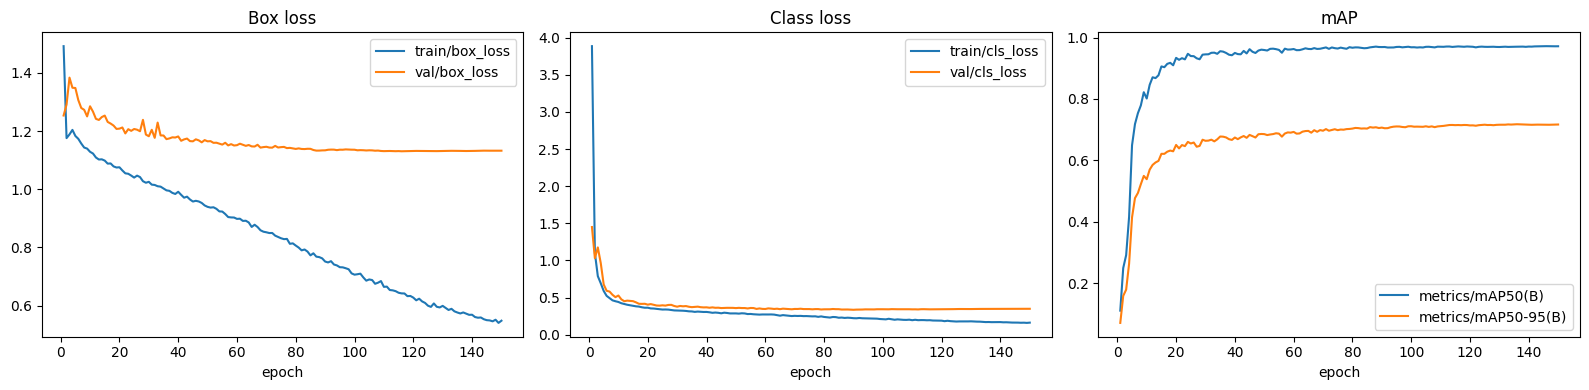

In [7]:
import matplotlib.pyplot as plt

df = pd.read_csv(RUN / "results.csv")
df.columns = df.columns.str.strip()
best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
print(f"Epochs: {len(df)}  best epoch {int(best['epoch'])}: "
      f"mAP@0.5 {best['metrics/mAP50(B)']:.4f}  mAP@0.5:0.95 {best['metrics/mAP50-95(B)']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for keys, ax, title in [
    (("train/box_loss", "val/box_loss"), axes[0], "Box loss"),
    (("train/cls_loss", "val/cls_loss"), axes[1], "Class loss"),
    (("metrics/mAP50(B)", "metrics/mAP50-95(B)"), axes[2], "mAP"),
]:
    for key in keys:
        ax.plot(df["epoch"], df[key], label=key)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## Test: characters

mAP on the test split, per class and by class kind.

In [8]:
model = YOLO(WEIGHTS)
metrics = model.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=config["batch"], device=DEVICE,
                    project=str(RUNS), name=f"{EXPERIMENT}-test", exist_ok=True, plots=False)
print(f"Test  P {metrics.box.mp:.4f}  R {metrics.box.mr:.4f}  "
      f"mAP@0.5 {metrics.box.map50:.4f}  mAP@0.5:0.95 {metrics.box.map:.4f}")

per_class = pd.DataFrame({
    "class": [CLASSES[i]["name"] for i in metrics.box.ap_class_index],
    "kind": [CLASSES[i]["kind"] for i in metrics.box.ap_class_index],
    "mAP50": metrics.box.ap50,
    "mAP50-95": metrics.box.ap,
})
print(per_class.groupby("kind")[["mAP50", "mAP50-95"]].mean().round(4))
print("\nWeakest classes:")
print(per_class.sort_values("mAP50").head(10).round(4).to_string(index=False))

Ultralytics 8.4.46 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                       CUDA:1 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 128 layers, 9,771,810 parameters, 0 gradients, 20.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 639.5±273.1 MB/s, size: 33.6 KB)
val: Scanning /kaggle/working/plate-reading/labels/test... 778 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 778/778 1.2Kit/s 0.6s0.0ss
val: New cache created: /kaggle/working/plate-reading/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.3it/s 4.0s0.3s
                   all        778       6560       0.95      0.908      0.956      0.695
                     0        341        433       0.98      0.952      0.964      0.641
                     1        617       1062      0.992      0.957       0.98      0.629
                     2        404        510      0.998

## Test: plate text

The detections of each crop are turned into plate text: boxes are split into a top and a bottom line at the largest vertical gap, each line is read left to right, and six digits are written as `12-3456`. The labels go through the same function, so the comparison does not depend on formatting.

- **Plate accuracy**: share of plates whose full text is correct.
- **Character error rate (CER)**: edit distance between predicted and true text, divided by the length of the true text.

In [9]:
BANGLA = [c["bangla"] for c in CLASSES]
KIND = [c["kind"] for c in CLASSES]


def plate_text(boxes):
    # boxes: (class, x_center, y_center, width, height), normalised
    if not boxes:
        return ""
    boxes = sorted(boxes, key=lambda b: b[2])
    lines = [boxes]
    if len(boxes) > 1:
        gaps = [boxes[i + 1][2] - boxes[i][2] for i in range(len(boxes) - 1)]
        split = max(range(len(gaps)), key=gaps.__getitem__)
        median_h = sorted(b[4] for b in boxes)[len(boxes) // 2]
        if gaps[split] > 0.5 * median_h:
            lines = [boxes[:split + 1], boxes[split + 1:]]
    out = []
    for line in lines:
        line = sorted(line, key=lambda b: b[1])
        tokens = [BANGLA[int(b[0])] for b in line]
        if all(KIND[int(b[0])] == "digit" for b in line):
            digits = "".join(tokens)
            out.append(f"{digits[:2]}-{digits[2:]}" if len(digits) == 6 else digits)
        else:
            # keep runs of digits together: ["ঢাকা", "১", "২"] -> "ঢাকা ১২"
            words = []
            for b, token in zip(line, tokens):
                if words and KIND[int(b[0])] == "digit" and words[-1][0] == "digit":
                    words[-1][1] += token
                else:
                    words.append([KIND[int(b[0])], token])
            out.append(" ".join(w for _, w in words))
    return " ".join(out)


def edit_distance(a, b):
    row = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, row[0] = row[0], i
        for j, cb in enumerate(b, 1):
            prev, row[j] = row[j], min(row[j] + 1, row[j - 1] + 1, prev + (ca != cb))
    return row[-1]


model = YOLO(WEIGHTS)
images = sorted((DATA / "images" / "test").iterdir())
rows = []
for start in range(0, len(images), 64):
    batch = images[start:start + 64]
    for path, result in zip(batch, model.predict(batch, imgsz=IMGSZ, device=DEVICE, agnostic_nms=True, verbose=False)):
        predicted = [(int(c), *xywh) for c, xywh in zip(result.boxes.cls.tolist(), result.boxes.xywhn.tolist())]
        label = DATA / "labels" / "test" / f"{path.stem}.txt"
        truth = [(int(p[0]), *map(float, p[1:])) for p in (l.split() for l in label.read_text().splitlines()) if p]
        t, p = plate_text(truth), plate_text(predicted)
        rows.append({"image": path.name, "source": path.name.split("__")[0], "truth": t, "predicted": p,
                     "correct": t == p, "errors": edit_distance(t, p), "length": len(t)})

plates = pd.DataFrame(rows)
for name, group in [("all", plates)] + list(plates.groupby("source")):
    print(f"{name:7} plates {len(group):4d}  plate accuracy {group['correct'].mean():.2%}  "
          f"CER {group['errors'].sum() / group['length'].sum():.2%}")
plates.to_csv(RUN / "test_plates.csv", index=False)
print("\nExamples of wrong plates:")
print(plates[~plates["correct"]].head(15)[["truth", "predicted"]].to_string(index=False))

all     plates  778  plate accuracy 78.79%  CER 6.35%
bd-lpr  plates  218  plate accuracy 76.15%  CER 4.54%
blpd    plates  560  plate accuracy 79.82%  CER 7.14%

Examples of wrong plates:
                       truth                     predicted
         ঢাকা মেট্রো ১৬-৩১৯০         ঢাকা মেট্রো ঘ ১৬-৩১৯০
              যশোর হ ১৩-০৬৫২           যশোর যশোর হ ১৩-০৬৫২
        ৩ ঢাকা ১৪ মেট্রো ৬৯৪       ৩ ঢাকা ১৪ মেট্রো ৬১ গ ৪
       ঢাকা মেট্রো ভ ১১-১৫৫০           ঢাকা মেট্রো ১১-১৫৫০
         ঢাকা মেট্রো গ ২৯৬৮২         ঢাকা মেট্রো গ ২৯-৬০৮২
     ১ ঢাকা ৭০ মেট্রো ৬৩ ঘ ৩         ঢাকা মেট্রো ঘ ১৭-০৬৩৩
         ঢাকা মেট্রো ২২-৭৯৪০         ঢাকা মেট্রো গ ২২-৭৯৪০
       মেট্রো ড ১ ঢাকা ১১১৯৭       ১ ঢাকা ১১ মেট্রো ১৯ ভ ৭
     ১১ ঢাকা ১৮ মেট্রো ৬ ড ৬         ঢাকা মেট্রো চ ১১-১৮৬৬
১ চট্টগ্রাম ৩৬ মেট্রো ৩৮ গ ১ ১ চট্টগ্রাম ৩৬ মেট্রো ৩৮ গ ১১
                ঢাকা ১১-৫৬৮৮           ঢাকা মেট্রো ১১-৫৬৮৮
       ঢাকা মেট্রো ব ১৪-৭০৭১           ঢাকা মেট্রো ১৪-৭৩৭১
               যশোর ট ০২০৩৬৮                

## Test: layout head

How often the head predicts the right count for each kind, and the whole layout, on the test plates.

In [10]:
core = YOLO(WEIGHTS).model
probs = layout_probabilities(core, images, IMGSZ, "cuda:0" if torch.cuda.is_available() else "cpu")
kind_of, caps = core.kind_index.tolist(), core.layout_caps

rows = []
for path, p in zip(images, probs):
    label = DATA / "labels" / "test" / f"{path.stem}.txt"
    counts = [0, 0, 0, 0]
    for line in label.read_text().splitlines():
        if line.strip():
            counts[kind_of[int(line.split()[0])]] += 1
    counts = [min(c, cap) for c, cap in zip(counts, caps)]
    pred = [int(x.argmax()) for x in p]
    row = {"source": path.name.split("__")[0], "layout correct": pred == counts}
    row.update({f"{k} count correct": a == b for k, a, b in zip(KINDS, pred, counts)})
    rows.append(row)

layout = pd.DataFrame(rows)
table = layout.groupby("source").mean().mul(100).round(1)
table.loc["all"] = layout.drop(columns="source").mean().mul(100).round(1)
table

,layout correct,digit count correct,district count correct,letter count correct,word count correct
source,,,,,
bd-lpr,89.0,99.1,98.6,91.7,98.6
blpd,97.7,99.6,98.4,99.6,98.8
all,95.2,99.5,98.5,97.4,98.7
